MODEL VALIDATION

## Part 1 - Data-centre load, capacity and minimum load vs. scenario results

**Goal.** Check that the flexible data-centre (DC) scenarios respect the limits implied by their inputs.

**Steps in this notebook**
1. Read the annual DC load per region from `base_dc/data/DE_DATACENTER.inc` and total it for 2025, 2030 and 2035.
2. Derive the reference values: capacity and minimum load for 20 %, 60 % and 100 % flexibility.
3. Extract the hourly DC load from the results of the three flexible scenarios.
4. Compare the results with the reference values.

**Reference values** (L = average DC load in MW = annual MWh / 8760; the DC profile is flat, `DE_VAR_T`)
- Capacity: the load is 80 % of the capacity, so C = L / 0.8 = 1.25 x L (the `DC_CAPFACTOR` of the scenarios).
- Minimum load with flexibility share s: L x (1 - s), i.e. 0.8 x L (20 %), 0.4 x L (60 %), 0 (100 %).

**Extracting the DC load from the results.** `EL_DEMAND_YCRST` has no separate DC entry; the DC load sits in the `EXOGENOUS` demand of the region. The `base_nodc` run keeps the DC load fixed at its 2025 value in every year, so
DC load = EXOGENOUS(scenario) - EXOGENOUS(base_nodc) + 2025 DC load / 8760 (per region and hour).
The share20 scenario simulates the full week (T001-T168), the share60 and share100 scenarios three days (T073-T144), so each is paired with the matching `base_nodc` result file.

**Things to know**
- The comparison uses the simulated hours only (4 weeks: S10, S24, S40, S50), not the full year.
- The hourly bounds apply per region, so the region-level check is the strict test; the system-level minimum can lie above L x (1 - s) when regions do not reach their minimum in the same hour.

In [13]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import gams.transfer as gt

warnings.filterwarnings("ignore", category=FutureWarning)

# ---- settings ---------------------------------------------------------------
# Paths relative to the Balmorel repository (the folder holding base/data), so the notebook runs on Windows and on the HPC
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "base" / "data").is_dir())
DC_FILE = ROOT / "base_dc" / "data" / "DE_DATACENTER.inc"
NODC_DIR = ROOT / "base_nodc"
YEARS = ["2025", "2030", "2035"]
HOURS_PER_YEAR = 8760
LOAD_SHARE_OF_CAP = 0.8                    # the load is 80 % of the capacity
CAP_FACTOR = 1 / LOAD_SHARE_OF_CAP         # C = 1.25 x L

# scenario folder -> flexible share, matching base_nodc result file
SCENARIOS = {
    "Flex_1_share20_cap125_12h":       {"share": 0.2, "nodc": "MainResults_fullweek.gdx"},
    "Flex_1_share60_cap125_12h_3day":  {"share": 0.6, "nodc": "MainResults_3days.gdx"},
    "Flex_1_share100_cap125_12h_3day": {"share": 1.0, "nodc": "MainResults_3days.gdx"},
}

### 1. Annual DC load and reference values

In [14]:
def read_gams_table(path):
    """Read a plain GAMS table (header row of years, then 'REGION v v v ...') into a DataFrame, regions as index.
    Lines that are not the header or a numeric row (TABLE line, comments, the statements after the table) are skipped."""
    header, data = None, {}
    for line in Path(path).read_text(encoding="latin1").splitlines():
        tok = line.split()
        if len(tok) < 2 or line.lstrip().startswith("*"):
            continue
        if tok[0].isdigit():                                       # header: 2024 2025 ...
            header = tok
        elif header and len(tok) == len(header) + 1:
            try:
                data[tok[0]] = [float(v) for v in tok[1:]]
            except ValueError:
                pass                                               # a GAMS statement, not a data row
    return pd.DataFrame(data, index=header).T


dc_annual = read_gams_table(DC_FILE)[YEARS]                    # MWh per region and year
dc_avg = dc_annual / HOURS_PER_YEAR                             # average (= constant) load L in MW

# DC load frozen in base_nodc (2025 value in every year), MW per region
dc_nodc = read_gams_table(NODC_DIR / "data" / "DE_DATACENTER.inc")["2025"] / HOURS_PER_YEAR

total = dc_annual.sum()
reference = pd.DataFrame({
    "Annual load (TWh)": total / 1e6,
    "Load L (MW)": total / HOURS_PER_YEAR,
    f"Capacity = L/{LOAD_SHARE_OF_CAP} (MW)": total / HOURS_PER_YEAR * CAP_FACTOR,
    "Min load 20 % flex = 0.8 L (MW)": total / HOURS_PER_YEAR * 0.8,
    "Min load 60 % flex = 0.4 L (MW)": total / HOURS_PER_YEAR * 0.4,
    "Min load 100 % flex = 0 (MW)": total / HOURS_PER_YEAR * 0.0,
}).T
reference.columns.name = "Year"
reference.round(1)

Year,2025,2030,2035
Annual load (TWh),95.1,133.8,226.5
Load L (MW),10860.0,15274.0,25856.2
Capacity = L/0.8 (MW),13575.0,19092.5,32320.2
Min load 20 % flex = 0.8 L (MW),8688.0,12219.2,20684.9
Min load 60 % flex = 0.4 L (MW),4344.0,6109.6,10342.5
Min load 100 % flex = 0 (MW),0.0,0.0,0.0


### 2. Hourly DC load from the scenario results

In [15]:
def read_exogenous(gdx):
    """Hourly EXOGENOUS electricity demand (MW) per year, region, season and hour from MainResults.gdx."""
    c = gt.Container()
    c.read(str(gdx), symbols=["EL_DEMAND_YCRST"])
    df = c["EL_DEMAND_YCRST"].records
    df.columns = ["Y", "C", "R", "S", "T", "type", "unit", "value"]
    df = df[df["type"] == "EXOGENOUS"]
    return df.groupby(["Y", "R", "S", "T"], observed=True)["value"].sum()


dc_load = {}                                                   # scenario -> Series (MW) indexed by (Y, R, S, T)
for name, cfg in SCENARIOS.items():
    scen = read_exogenous(ROOT / name / "model" / "MainResults.gdx")
    nodc = read_exogenous(NODC_DIR / "model" / cfg["nodc"])
    delta = (scen - nodc).dropna()                             # DC load above the frozen 2025 level
    delta = delta[delta.index.get_level_values("R").isin(dc_avg.index)]   # regions without DC load in the input are left out
    regions = delta.index.get_level_values("R")
    dc_load[name] = delta + dc_nodc.reindex(regions).values
    print(f"{name}: {delta.index.droplevel(['Y', 'R']).nunique()} hours per region, {regions.nunique()} regions")

/work3/s243704/envs/pybalmorel/lib/python3.12/site-packages/gams/transfer/containers/_container.py:71: UserWarning: The GAMS version (50.4.1) differs from the API version (54.6.0).
  ws = GamsWorkspace()


Flex_1_share20_cap125_12h: 672 hours per region, 41 regions
Flex_1_share60_cap125_12h_3day: 288 hours per region, 41 regions
Flex_1_share100_cap125_12h_3day: 288 hours per region, 41 regions


### 3. Comparison with the reference values

System level = sum over all regions per hour (MW). Region level = the worst region, as a ratio to its own L (so the expected minimum is 1 - s and the expected maximum is the capacity factor, 1.25).

In [16]:
rows = []
for name, cfg in SCENARIOS.items():
    s = cfg["share"]
    load = dc_load[name]
    for y in YEARS:
        sys_hourly = load.loc[y].groupby(["S", "T"]).sum()               # system DC load per hour
        ratio = load.loc[y] / dc_avg[y].reindex(load.loc[y].index.get_level_values("R")).values
        L = total[y] / HOURS_PER_YEAR
        rows.append({
            "Scenario": name, "Year": y, "Flex share": s,
            "L (MW)": L,
            "Mean load (MW)": sys_hourly.mean(),
            "Min load (MW)": sys_hourly.min(), "Expected min (MW)": L * (1 - s),
            "Peak load (MW)": sys_hourly.max(), "Capacity (MW)": L * CAP_FACTOR,
            "Region min / L": ratio.min(), "Expected min / L": 1 - s,
            "Region peak / L": ratio.max(), "Expected max / L": CAP_FACTOR,
        })
comparison = pd.DataFrame(rows).set_index(["Scenario", "Year"])

# deviation of the regional extremes from the bounds (tolerance for solver precision)
TOL = 1e-3
comparison["Min respected"] = comparison["Region min / L"] >= comparison["Expected min / L"] - TOL
comparison["Cap respected"] = comparison["Region peak / L"] <= comparison["Expected max / L"] + TOL
comparison.round(3)

Flex share     L (MW)  Mean load (MW)  \
Scenario                        Year                                          
Flex_1_share20_cap125_12h       2025         0.2  10859.970       10859.969   
                                2030         0.2  15273.973       15273.973   
                                2035         0.2  25856.164       25856.164   
Flex_1_share60_cap125_12h_3day  2025         0.6  10859.970       10859.970   
                                2030         0.6  15273.973       15273.973   
                                2035         0.6  25856.164       25856.164   
Flex_1_share100_cap125_12h_3day 2025         1.0  10859.970       10859.970   
                                2030         1.0  15273.973       15273.973   
                                2035         1.0  25856.164       25856.164   

                                      Min load (MW)  Expected min (MW)  \
Scenario                        Year                                     
Flex_1_share20_cap125_12h       2025       8687.976           8687.976   
                                2030      12219.178          12219.178   
                                2035      20684.931          20684.931   
Flex_1_share60_cap125_12h_3day  2025       4749.242           4343.988   
                                2030       6915.558           6109.589   
                                2035      11103.024          10342.466   
Flex_1_share100_cap125_12h_3day 2025       1530.771              0.000   
                                2030       1529.716              0.000   
                                2035       1199.917              0.000   

                                      Peak load (MW)  Capacity (MW)  \
Scenario                        Year                                  
Flex_1_share20_cap125_12h       2025       13574.962      13574.962   
                                2030       19092.466      19092.466   
                                2035       32320.205      32320.205   
Flex_1_share60_cap125_12h_3day  2025       13574.962      13574.962   
                                2030       19092.466      19092.466   
                                2035       32320.205      32320.205   
Flex_1_share100_cap125_12h_3day 2025       13574.962      13574.962   
                                2030       19092.466      19092.466   
                                2035       32320.205      32320.205   

                                      Region min / L  Expected min / L  \
Scenario                        Year                                     
Flex_1_share20_cap125_12h       2025             0.8               0.8   
                                2030             0.8               0.8   
                                2035             0.8               0.8   
Flex_1_share60_cap125_12h_3day  2025             0.4               0.4   
                                2030             0.4               0.4   
                                2035             0.4               0.4   
Flex_1_share100_cap125_12h_3day 2025            -0.0               0.0   
                                2030            -0.0               0.0   
                                2035            -0.0               0.0   

                                      Region peak / L  Expected max / L  \
Scenario                        Year                                      
Flex_1_share20_cap125_12h       2025             1.25              1.25   
                                2030             1.25              1.25   
                                2035             1.25              1.25   
Flex_1_share60_cap125_12h_3day  2025             1.25              1.25   
                                2030             1.25              1.25   
                                2035             1.25              1.25   
Flex_1_share100_cap125_12h_3day 2025             1.25              1.25   
                                2030             1.25              1.25   
      

In [17]:
# how much of the allowed flexible range is used: mean load vs L, and share of hours at the minimum / at the capacity
rows = []
for name, cfg in SCENARIOS.items():
    for y in YEARS:
        load = dc_load[name].loc[y]
        L = dc_avg[y].reindex(load.index.get_level_values("R")).values
        ratio = load.values / L
        rows.append({
            "Scenario": name, "Year": y,
            "Mean / L": ratio.mean(),
            "Hours at min (%)": 100 * np.mean(ratio <= 1 - cfg["share"] + TOL),
            "Hours at capacity (%)": 100 * np.mean(ratio >= CAP_FACTOR - TOL),
        })
pd.DataFrame(rows).set_index(["Scenario", "Year"]).round(3)

Mean / L  Hours at min (%)  \
Scenario                        Year                               
Flex_1_share20_cap125_12h       2025       1.0            50.036   
                                2030       1.0            49.746   
                                2035       1.0            48.762   
Flex_1_share60_cap125_12h_3day  2025       1.0            27.363   
                                2030       1.0            27.253   
                                2035       1.0            27.143   
Flex_1_share100_cap125_12h_3day 2025       1.0            18.318   
                                2030       1.0            17.598   
                                2035       1.0            17.615   

                                      Hours at capacity (%)  
Scenario                        Year                         
Flex_1_share20_cap125_12h       2025                 39.442  
                                2030                 39.111  
                                2035                 38.204  
Flex_1_share60_cap125_12h_3day  2025                 68.149  
                                2030                 67.658  
                                2035                 67.801  
Flex_1_share100_cap125_12h_3day 2025                 77.642  
                                2030                 76.922  
                                2035                 76.778

## Part 2 - System results of the flexible scenarios vs. base_dc

**Goal.** Compare the system cost, CO2 emissions, electricity marginal cost and curtailment of the three validated flexible scenarios (20 %, 60 % and 100 % flexibility) with the `base_dc` scenario without flexibility, per solved year (same metrics as the summary table of the `NOTEBOOK_PostProcessing` in `base_dc`).

**Metrics** (annual results, from `MainResults.gdx`)
- Total system cost: `OBJ_YCR`, summed over regions (Mmoney).
- CO2 emissions: `EMI_YCRAG`, summed (kton).
- Electricity marginal cost: `EL_PRICE_YCR` (AVERAGE) per region, weighted by the annual electricity demand of the region (`EL_DEMAND_YCR`), Money/MWh.
- Curtailment: curtailed / (dispatched + curtailed) electricity of onshore wind, offshore wind and solar (%).

**Time resolution - not like for like.** The requested base is `base_dc` with 3 days per season (`MainResults_3day.gdx`). Share60 and share100 were also run with 3 days, but share20 was run with the full week (168 h per season). The two base_dc runs differ clearly (e.g. about 2,100-3,100 Mmoney higher cost and about twice the curtailment with the full week), so share20 against the 3-day base would mix the effect of flexibility with the effect of the resolution. All scenarios are therefore compared with the 3-day base as requested (3.1), and share20 is in addition compared with the `base_dc` full-week run (3.2).

In [18]:
from pybalmorel import MainResults

# ---- settings ---------------------------------------------------------------
RESULT_RUNS = {                                  # label -> (scenario folder, results file)
    "base_dc 3day":      ("base_dc", "MainResults_3day.gdx"),
    "base_dc full week": ("base_dc", "MainResults_fullweek.gdx"),
    "share20 (full week)": ("Flex_1_share20_cap125_12h", "MainResults.gdx"),
    "share60 (3day)":    ("Flex_1_share60_cap125_12h_3day", "MainResults.gdx"),
    "share100 (3day)":   ("Flex_1_share100_cap125_12h_3day", "MainResults.gdx"),
}
BASE_3DAY, BASE_WEEK = "base_dc 3day", "base_dc full week"
FLEX_RUNS = ["share20 (full week)", "share60 (3day)", "share100 (3day)"]
VRE_CURT_TECH = ["WIND-ON", "WIND-OFF", "SOLAR-PV"]
# pybalmorel returns some symbols with the raw GAMS column names; map them to one naming scheme
RENAME = {"Y": "Year", "C": "Country", "RRR": "Region", "AAA": "Area", "G": "Generation", "FFF": "Fuel",
          "TECH_TYPE": "Technology", "COMMODITY": "Commodity", "CATEGORY": "Category"}

In [19]:
def run_metrics(folder, file, label):
    """System cost, CO2, demand-weighted marginal electricity cost and VRE curtailment per solved year of one run."""
    res = MainResults(files=file, paths=str(ROOT / folder / "model"), scenario_names=[label])
    get = lambda symbol: res.get_result(symbol).rename(columns=RENAME).assign(Year=lambda d: d["Year"].astype(str))
    total = lambda symbol: get(symbol).groupby("Year")["Value"].sum()

    # curtailment rate of onshore wind, offshore wind and solar electricity (%)
    vre = lambda t: t[t["Technology"].isin(VRE_CURT_TECH) & t["Commodity"].eq("ELECTRICITY")].groupby("Year")["Value"].sum()
    curtailed, dispatched = vre(get("CURT_YCRAGF")), vre(get("PRO_YCRAGF"))

    # marginal cost: time-averaged EL_PRICE_YCR per region, weighted by the annual electricity demand of the region
    price = get("EL_PRICE_YCR")
    price = price[price["Category"].eq("AVERAGE")].set_index(["Year", "Region"])["Value"].rename("Price")
    demand = get("EL_DEMAND_YCR").groupby(["Year", "Region"])["Value"].sum().rename("Demand")
    pd_ = pd.concat([price, demand], axis=1).fillna({"Demand": 0})
    marginal = (pd_["Price"] * pd_["Demand"]).groupby("Year").sum() / pd_["Demand"].groupby("Year").sum()

    return pd.DataFrame({
        "Total cost (Mmoney)": total("OBJ_YCR"),
        "CO2 emissions (kton)": total("EMI_YCRAG"),
        "Electricity marginal cost (Money/MWh, demand-weighted)": marginal,
        "Curtailment (% of onshore wind, offshore wind & solar available)": curtailed / (curtailed + dispatched) * 100,
    })


metrics = {label: run_metrics(folder, file, label) for label, (folder, file) in RESULT_RUNS.items()}
metrics = pd.concat(metrics, names=["Run", "Year"]).stack().rename("Value").reset_index(name="Value").rename(columns={"level_2": "Metric"})
metrics = metrics.pivot_table(index=["Metric", "Year"], columns="Run", values="Value", sort=False)[list(RESULT_RUNS)]
metrics.round(2)

/work3/s243704/envs/pybalmorel/lib/python3.12/site-packages/pybalmorel/classes.py:110: UserWarning: The GAMS version (50.4.1) differs from the API version (54.6.0).
  ws = gams.GamsWorkspace()
/work3/s243704/envs/pybalmorel/lib/python3.12/site-packages/pybalmorel/classes.py:110: UserWarning: The GAMS version (50.4.1) differs from the API version (54.6.0).
  ws = gams.GamsWorkspace()
/work3/s243704/envs/pybalmorel/lib/python3.12/site-packages/pybalmorel/classes.py:110: UserWarning: The GAMS version (50.4.1) differs from the API version (54.6.0).
  ws = gams.GamsWorkspace()
/work3/s243704/envs/pybalmorel/lib/python3.12/site-packages/pybalmorel/classes.py:110: UserWarning: The GAMS version (50.4.1) differs from the API version (54.6.0).
  ws = gams.GamsWorkspace()


Loading /work3/s243704/Balmorel/base_dc/model/MainResults_3day.gdx
Loading /work3/s243704/Balmorel/base_dc/model/MainResults_fullweek.gdx
Loading /work3/s243704/Balmorel/Flex_1_share20_cap125_12h/model/MainResults.gdx
Loading /work3/s243704/Balmorel/Flex_1_share60_cap125_12h_3day/model/MainResults.gdx
Loading /work3/s243704/Balmorel/Flex_1_share100_cap125_12h_3day/model/MainResults.gdx


/work3/s243704/envs/pybalmorel/lib/python3.12/site-packages/pybalmorel/classes.py:110: UserWarning: The GAMS version (50.4.1) differs from the API version (54.6.0).
  ws = gams.GamsWorkspace()


Run                                                      base_dc 3day  \
Metric                                             Year                 
Total cost (Mmoney)                                2025     237380.60   
                                                   2030     249754.39   
                                                   2035     267099.25   
CO2 emissions (kton)                               2025     129086.44   
                                                   2030     100373.66   
                                                   2035      87533.36   
Electricity marginal cost (Money/MWh, demand-we... 2025         36.68   
                                                   2030         37.00   
                                                   2035         39.70   
Curtailment (% of onshore wind, offshore wind &... 2025          0.55   
                                                   2030          0.28   
                                                   2035          0.33   

Run                                                      base_dc full week  \
Metric                                             Year                      
Total cost (Mmoney)                                2025          239524.92   
                                                   2030          252325.59   
                                                   2035          270177.59   
CO2 emissions (kton)                               2025          128815.37   
                                                   2030          103999.93   
                                                   2035           91704.13   
Electricity marginal cost (Money/MWh, demand-we... 2025              37.46   
                                                   2030              38.27   
                                                   2035              40.88   
Curtailment (% of onshore wind, offshore wind &... 2025               1.07   
                                                   2030               0.66   
                                                   2035               0.59   

Run                                                      share20 (full week)  \
Metric                                             Year                        
Total cost (Mmoney)                                2025            239256.75   
                                                   2030            251971.16   
                                                   2035            269561.95   
CO2 emissions (kton)                               2025            127834.57   
                                                   2030            103069.36   
                                                   2035             91015.75   
Electricity marginal cost (Money/MWh, demand-we... 2025                37.38   
                                                   2030                38.14   
                                                   2035                40.65   
Curtailment (% of onshore wind, offshore wind &... 2025                 1.06   
                                                   2030                 0.66   
                                                   2035                 0.58   

Run                                                      share60 (3day)  \
Metric                                             Year                   
Total cost (Mmoney)                                2025       236846.89   
                                                   2030       249074.82   
                                                   2035       265886.85   
CO2 emissions (kton)                               2025       127241.25   
                                                   2030        98231.53   
                                                   2035        85272.90   
Electricity marginal cost (Money/MWh, demand-we... 2025           36.56   
                                                   2030           36.66   
             

### 3.1 All flexible scenarios vs. base_dc 3-day (as requested)

Change = scenario - base. Share20 uses the full week, so its change here includes the resolution effect (see 3.2).

In [20]:
def change_table(base, runs):
    """Base value, the value of each run and its change (absolute and %) with respect to `base`."""
    out = {base: metrics[base]}
    for r in runs:
        out[r] = metrics[r]
        out[(r, "change")] = metrics[r] - metrics[base]
        out[(r, "change %")] = (metrics[r] - metrics[base]) / metrics[base] * 100
    table = pd.concat({(k if isinstance(k, tuple) else (k, "value")): v for k, v in out.items()}, axis=1)
    table.columns.names = ["Run", ""]
    return table


vs_3day = change_table(BASE_3DAY, FLEX_RUNS)
vs_3day.round(2)

Run                                                     base_dc 3day  \
                                                               value   
Metric                                             Year                
Total cost (Mmoney)                                2025    237380.60   
                                                   2030    249754.39   
                                                   2035    267099.25   
CO2 emissions (kton)                               2025    129086.44   
                                                   2030    100373.66   
                                                   2035     87533.36   
Electricity marginal cost (Money/MWh, demand-we... 2025        36.68   
                                                   2030        37.00   
                                                   2035        39.70   
Curtailment (% of onshore wind, offshore wind &... 2025         0.55   
                                                   2030         0.28   
                                                   2035         0.33   

Run                                                     share20 (full week)  \
                                                                      value   
Metric                                             Year                       
Total cost (Mmoney)                                2025           239256.75   
                                                   2030           251971.16   
                                                   2035           269561.95   
CO2 emissions (kton)                               2025           127834.57   
                                                   2030           103069.36   
                                                   2035            91015.75   
Electricity marginal cost (Money/MWh, demand-we... 2025               37.38   
                                                   2030               38.14   
                                                   2035               40.65   
Curtailment (% of onshore wind, offshore wind &... 2025                1.06   
                                                   2030                0.66   
                                                   2035                0.58   

Run                                                                        \
                                                          change change %   
Metric                                             Year                     
Total cost (Mmoney)                                2025  1876.15     0.79   
                                                   2030  2216.77     0.89   
                                                   2035  2462.70     0.92   
CO2 emissions (kton)                               2025 -1251.87    -0.97   
                                                   2030  2695.70     2.69   
                                                   2035  3482.39     3.98   
Electricity marginal cost (Money/MWh, demand-we... 2025     0.69     1.89   
                                                   2030     1.14     3.09   
                                                   2035     0.95     2.40   
Curtailment (% of onshore wind, offshore wind &... 2025     0.51    91.35   
                                                   2030     0.38   135.45   
                                                   2035     0.25    74.78   

Run                                                     share60 (3day)  \
                                                                 value   
Metric                                             Year                  
Total cost (Mmoney)                                2025      236846.89   
                                                   2030      249074.82   
                                                   2035      265886.85   
CO2 emissions (kton)                               2025      127241.25   
                                                   2030    

### 3.2 Share20 vs. base_dc full week (same time resolution)

In [21]:
change_table(BASE_WEEK, ["share20 (full week)"]).round(2)

Run                                                     base_dc full week  \
                                                                    value   
Metric                                             Year                     
Total cost (Mmoney)                                2025         239524.92   
                                                   2030         252325.59   
                                                   2035         270177.59   
CO2 emissions (kton)                               2025         128815.37   
                                                   2030         103999.93   
                                                   2035          91704.13   
Electricity marginal cost (Money/MWh, demand-we... 2025             37.46   
                                                   2030             38.27   
                                                   2035             40.88   
Curtailment (% of onshore wind, offshore wind &... 2025              1.07   
                                                   2030              0.66   
                                                   2035              0.59   

Run                                                     share20 (full week)  \
                                                                      value   
Metric                                             Year                       
Total cost (Mmoney)                                2025           239256.75   
                                                   2030           251971.16   
                                                   2035           269561.95   
CO2 emissions (kton)                               2025           127834.57   
                                                   2030           103069.36   
                                                   2035            91015.75   
Electricity marginal cost (Money/MWh, demand-we... 2025               37.38   
                                                   2030               38.14   
                                                   2035               40.65   
Curtailment (% of onshore wind, offshore wind &... 2025                1.06   
                                                   2030                0.66   
                                                   2035                0.58   

Run                                                                       
                                                         change change %  
Metric                                             Year                   
Total cost (Mmoney)                                2025 -268.17    -0.11  
                                                   2030 -354.43    -0.14  
                                                   2035 -615.64    -0.23  
CO2 emissions (kton)                               2025 -980.80    -0.76  
                                                   2030 -930.57    -0.89  
                                                   2035 -688.38    -0.75  
Electricity marginal cost (Money/MWh, demand-we... 2025   -0.08    -0.22  
                                                   2030   -0.12    -0.33  
                                                   2035   -0.23    -0.57  
Curtailment (% of onshore wind, offshore wind &... 2025   -0.01    -1.25  
                                                   2030    0.00     0.16  
                                                   2035   -0.02    -2.60

### 3.3 Changes relative to the base (%)

Share20 is shown against the full-week base, share60 and share100 against the 3-day base (same resolution in each pair).

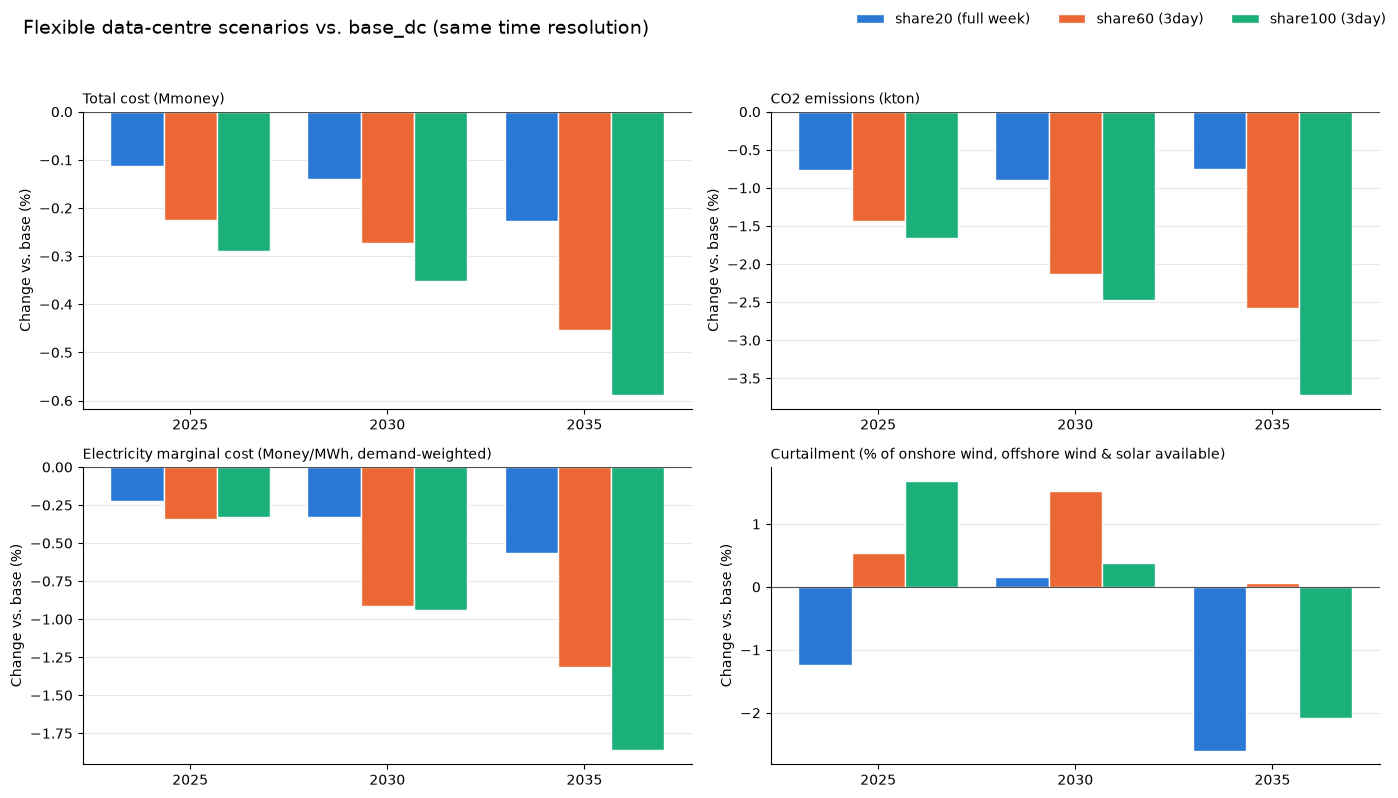

In [22]:
import matplotlib.pyplot as plt

PAIRS = {"share20 (full week)": BASE_WEEK, "share60 (3day)": BASE_3DAY, "share100 (3day)": BASE_3DAY}
COLORS = {"share20 (full week)": "#2a78d6", "share60 (3day)": "#eb6834", "share100 (3day)": "#1baf7a"}   # categorical, fixed per scenario
rel = {r: (metrics[r] - metrics[b]) / metrics[b] * 100 for r, b in PAIRS.items()}

names = list(metrics.index.get_level_values("Metric").unique())
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, name in zip(axes.ravel(), names):
    for k, (r, series) in enumerate(rel.items()):
        s = series.loc[name]
        ax.bar(np.arange(len(s)) + (k - 1) * 0.27, s.values, 0.27, color=COLORS[r], label=r, edgecolor="#fcfcfb")
    ax.set_xticks(range(len(s))); ax.set_xticklabels(s.index)
    ax.axhline(0, color="#52514e", linewidth=0.8)
    ax.set_title(name, loc="left", fontsize=10); ax.set_ylabel("Change vs. base (%)")
    ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
    for side in ("top", "right"): ax.spines[side].set_visible(False)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncol=3, frameon=False)
plt.suptitle("Flexible data-centre scenarios vs. base_dc (same time resolution)", x=0.02, ha="left", fontsize=14)
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

## Part 3 - Hourly data-centre load change relative to base_dc (all regions)

The change in the data-centre electricity demand per hour relative to `base_dc`, summed over all regions (GWh), laid out as Figure 3 of Senga, Wang & Knittel (2026, *iScience* 116497) and as 2.8.8 of the `Flex_1` post-processing: hour of the day on the y-axis, modelled day on the x-axis, **red = load added (workload shifted in), green = load reduced (workload shifted out)**.

- **Panels**: rows = shifting horizon (1, 12, 24 h), columns = flexible share (20, 60, 100 %).
- **Which run**: for every share and horizon the 3-day run (`..._3day`) if it exists, otherwise the full-week run. Only the 20 % runs have no 3-day version, so the first column shows 4 seasons x 7 days (full week) and the other two columns 4 seasons x 3 days (Thu-Sat).
- **Baseline**: `base_dc` with the same run length as the scenario (`MainResults_3day.gdx` or `MainResults_fullweek.gdx`). The change is the `EXOGENOUS` category of `EL_DEMAND_YCRST` of the flexible run minus that of `base_dc`; all other exogenous demand is identical, so the difference is only the data-centre shift.
- **Days** are the modelled days only (not the 365 days of the paper). Share and horizon are read from the `DC_FLEXPARAM.inc` of each run. One colour scale is used for all panels.

In [23]:
import re
import gams.transfer as gt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

# ---- settings ---------------------------------------------------------------
FIG3_YEAR = "2035"
FIG3_BASE_FILES = {"3day": ROOT / "base_dc" / "model" / "MainResults_3day.gdx",          # base_dc with the same run length
                   "fullweek": ROOT / "base_dc" / "model" / "MainResults_fullweek.gdx"}
FIG3_CMAP = LinearSegmentedColormap.from_list("green_white_red", ["#006d2c", "#74c476", "#ffffff", "#fb6a4a", "#cb181d"])
FIG3_DAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]


def fig3_exogenous(path):
    """EXOGENOUS electricity demand (MW) per region, season and time step in FIG3_YEAR; includes the served data-centre load."""
    c = gt.Container()
    c.read(str(path), symbols=["EL_DEMAND_YCRST"])
    r = c["EL_DEMAND_YCRST"].records
    r = r.loc[r["Y"].astype(str).eq(FIG3_YEAR) & r["VARIABLE_CATEGORY"].astype(str).eq("EXOGENOUS")]
    return r.astype({k: str for k in ["RRR", "SSS", "TTT"]}).set_index(["RRR", "SSS", "TTT"])["value"].rename_axis(["Region", "Season", "Time"])


def fig3_params(folder):
    """(flexible share, shifting horizon) of a run, from the DC_FLEXPARAM.inc of its data folder."""
    text = (folder / "data" / "DC_FLEXPARAM.inc").read_text()
    get = lambda name: float(re.search(rf"SCALAR\s+{name}\b[^/]*/\s*([\d.]+)\s*/", text).group(1))
    return get("DC_FLEXSHARE"), get("DC_SHIFTHORIZON")


# one run per (share, horizon): the 3-day run if available, otherwise the full-week run
runs = {}
for folder in sorted(ROOT.glob("Flex_1_share*_cap125_*h*")):
    if not (folder / "model" / "MainResults.gdx").exists():
        continue
    share, horizon = fig3_params(folder)
    three_day = folder.name.endswith("_3day")
    if (share, horizon) not in runs or three_day:
        runs[(share, horizon)] = (folder, three_day)
for (share, horizon), (folder, three_day) in sorted(runs.items()):
    print(f"share {share:g}, horizon {horizon:g} h: {folder.name}")

share 0.2, horizon 1 h: Flex_1_share20_cap125_1h
share 0.2, horizon 12 h: Flex_1_share20_cap125_12h
share 0.2, horizon 24 h: Flex_1_share20_cap125_24h
share 0.6, horizon 1 h: Flex_1_share60_cap125_1h_3day
share 0.6, horizon 12 h: Flex_1_share60_cap125_12h_3day
share 0.6, horizon 24 h: Flex_1_share60_cap125_24h_3day
share 1, horizon 1 h: Flex_1_share100_cap125_1h_3day
share 1, horizon 12 h: Flex_1_share100_cap125_12h_3day
share 1, horizon 24 h: Flex_1_share100_cap125_24h_3day


In [24]:
base_exo = {}                                                # base_dc EXOGENOUS demand per run length, read once
fig3 = {}                                                    # (share, horizon) -> hour-of-day x day table (GWh)
for (share, horizon), (folder, three_day) in sorted(runs.items()):
    key = "3day" if three_day else "fullweek"
    if key not in base_exo:
        base_exo[key] = fig3_exogenous(FIG3_BASE_FILES[key])
    exo_run = fig3_exogenous(folder / "model" / "MainResults.gdx")
    change = exo_run.sub(base_exo[key], fill_value=0)                              # MW per region and time step
    times = sorted(change.index.get_level_values("Time").unique())
    hour = np.array([int(t[1:]) - 1 for t in times])                                # hour of the week (T001 = Monday 00:00)
    step_h = int(np.diff(hour).min())                                               # hours per time step
    eu = change.groupby(level=["Season", "Time"]).sum() * step_h / 1e3             # GWh per step, all regions
    t = eu.index.get_level_values("Time").str[1:].astype(int) - 1
    grid = pd.DataFrame({"Value": eu.to_numpy(), "Hour": t % 24, "Season": eu.index.get_level_values("Season"),
                         "Day": [FIG3_DAYS[d % 7] for d in t // 24], "DayNo": t // 24})
    grid = grid.pivot_table(index="Hour", columns=["Season", "DayNo", "Day"], values="Value", aggfunc="sum").reindex(range(24))
    fig3[(share, horizon)] = grid
    print(f"share {share:g}, h = {horizon:g}: {folder.name} vs base_dc {key}: {eu.clip(lower=0).sum():,.1f} GWh shifted in, "
          f"largest hourly change {eu.abs().max():.2f} GWh")

/work3/s243704/envs/pybalmorel/lib/python3.12/site-packages/gams/transfer/containers/_container.py:71: UserWarning: The GAMS version (50.4.1) differs from the API version (54.6.0).
  ws = GamsWorkspace()
/work3/s243704/envs/pybalmorel/lib/python3.12/site-packages/gams/transfer/containers/_container.py:71: UserWarning: The GAMS version (50.4.1) differs from the API version (54.6.0).
  ws = GamsWorkspace()


share 0.2, h = 1: Flex_1_share20_cap125_1h vs base_dc fullweek: 553.0 GWh shifted in, largest hourly change 5.30 GWh
share 0.2, h = 12: Flex_1_share20_cap125_12h vs base_dc fullweek: 1,091.1 GWh shifted in, largest hourly change 6.46 GWh


/work3/s243704/envs/pybalmorel/lib/python3.12/site-packages/gams/transfer/containers/_container.py:71: UserWarning: The GAMS version (50.4.1) differs from the API version (54.6.0).
  ws = GamsWorkspace()
/work3/s243704/envs/pybalmorel/lib/python3.12/site-packages/gams/transfer/containers/_container.py:71: UserWarning: The GAMS version (50.4.1) differs from the API version (54.6.0).
  ws = GamsWorkspace()


share 0.2, h = 24: Flex_1_share20_cap125_24h vs base_dc fullweek: 1,185.8 GWh shifted in, largest hourly change 6.46 GWh
share 0.6, h = 1: Flex_1_share60_cap125_1h_3day vs base_dc 3day: 576.8 GWh shifted in, largest hourly change 13.09 GWh


/work3/s243704/envs/pybalmorel/lib/python3.12/site-packages/gams/transfer/containers/_container.py:71: UserWarning: The GAMS version (50.4.1) differs from the API version (54.6.0).
  ws = GamsWorkspace()
/work3/s243704/envs/pybalmorel/lib/python3.12/site-packages/gams/transfer/containers/_container.py:71: UserWarning: The GAMS version (50.4.1) differs from the API version (54.6.0).
  ws = GamsWorkspace()
/work3/s243704/envs/pybalmorel/lib/python3.12/site-packages/gams/transfer/containers/_container.py:71: UserWarning: The GAMS version (50.4.1) differs from the API version (54.6.0).
  ws = GamsWorkspace()


share 0.6, h = 12: Flex_1_share60_cap125_12h_3day vs base_dc 3day: 779.8 GWh shifted in, largest hourly change 14.75 GWh
share 0.6, h = 24: Flex_1_share60_cap125_24h_3day vs base_dc 3day: 776.3 GWh shifted in, largest hourly change 14.75 GWh
share 1, h = 1: Flex_1_share100_cap125_1h_3day vs base_dc 3day: 750.2 GWh shifted in, largest hourly change 20.92 GWh
share 1, h = 12: Flex_1_share100_cap125_12h_3day vs base_dc 3day: 906.3 GWh shifted in, largest hourly change 24.66 GWh


/work3/s243704/envs/pybalmorel/lib/python3.12/site-packages/gams/transfer/containers/_container.py:71: UserWarning: The GAMS version (50.4.1) differs from the API version (54.6.0).
  ws = GamsWorkspace()
/work3/s243704/envs/pybalmorel/lib/python3.12/site-packages/gams/transfer/containers/_container.py:71: UserWarning: The GAMS version (50.4.1) differs from the API version (54.6.0).
  ws = GamsWorkspace()
/work3/s243704/envs/pybalmorel/lib/python3.12/site-packages/gams/transfer/containers/_container.py:71: UserWarning: The GAMS version (50.4.1) differs from the API version (54.6.0).
  ws = GamsWorkspace()
/work3/s243704/envs/pybalmorel/lib/python3.12/site-packages/gams/transfer/containers/_container.py:71: UserWarning: The GAMS version (50.4.1) differs from the API version (54.6.0).
  ws = GamsWorkspace()


share 1, h = 24: Flex_1_share100_cap125_24h_3day vs base_dc 3day: 900.8 GWh shifted in, largest hourly change 24.66 GWh


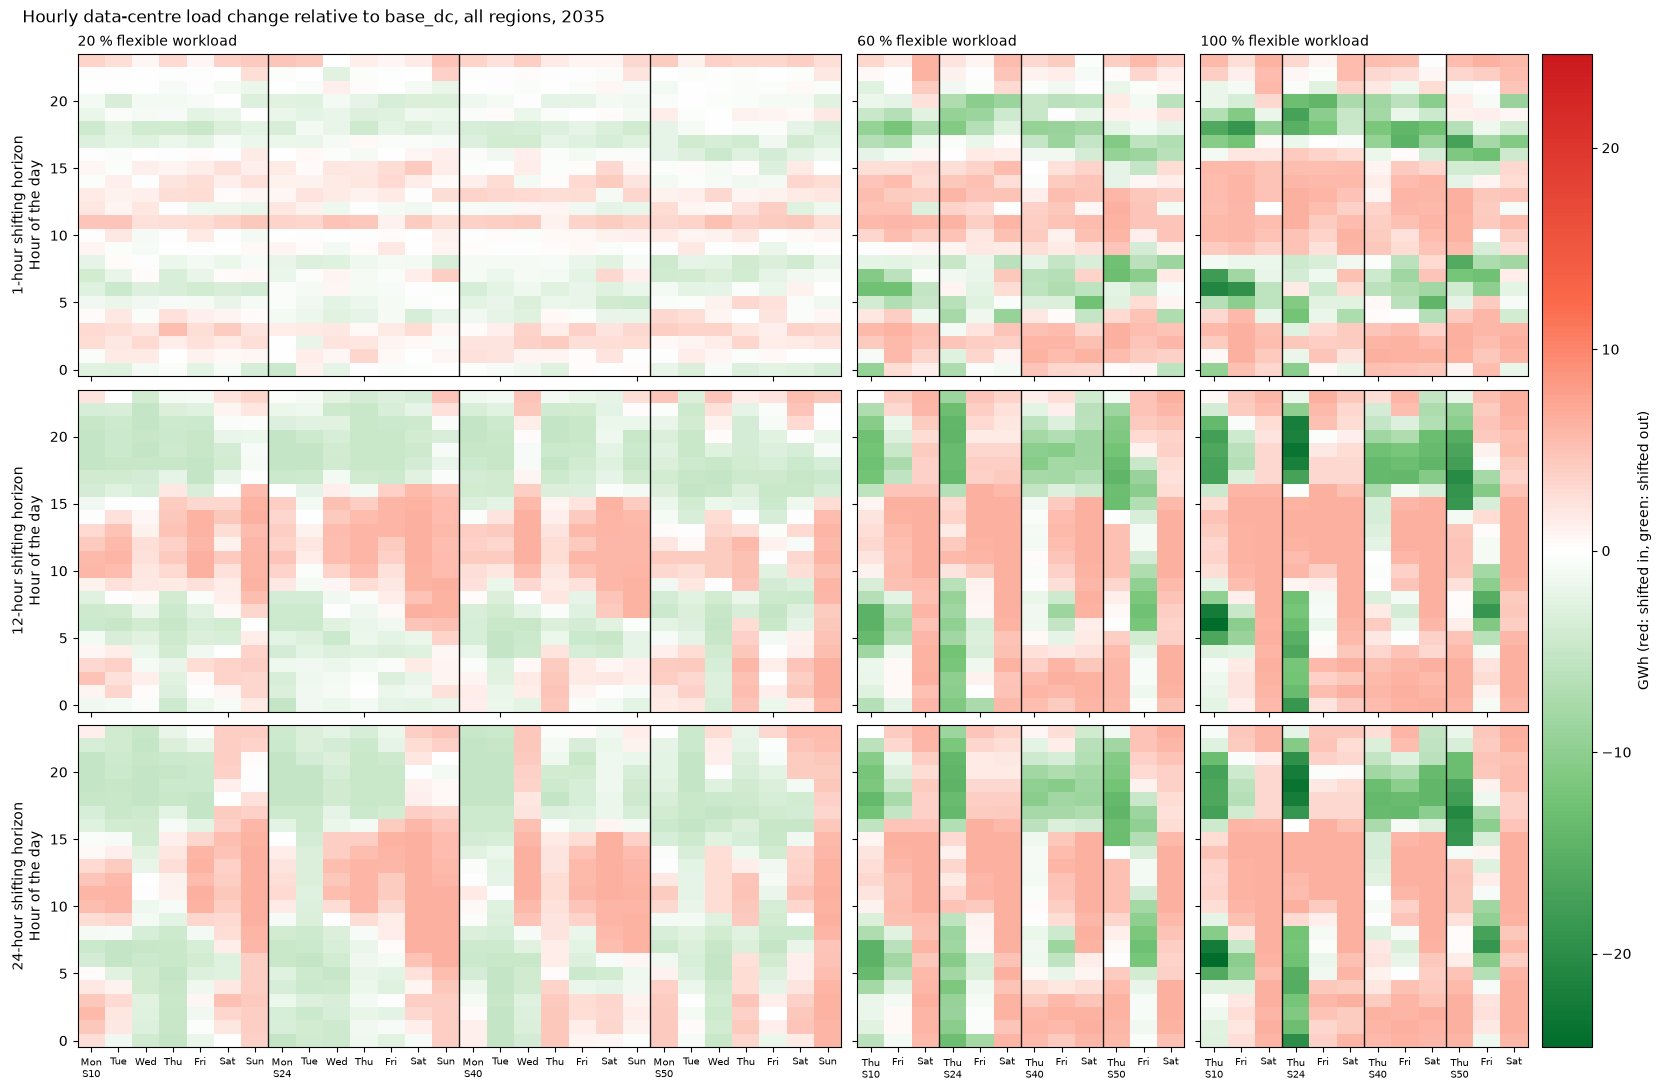

In [25]:
shares = sorted({s for s, _ in fig3})
horizons = sorted({h for _, h in fig3})
lim = max(np.nanmax(np.abs(g.to_numpy())) for g in fig3.values())
norm = TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim)

fig, axes = plt.subplots(len(horizons), len(shares), figsize=(5 * len(shares) + 1.5, 3.2 * len(horizons) + 1.2),
                         squeeze=False, layout="constrained", gridspec_kw={"width_ratios": [28 if s == 0.2 else 12 for s in shares]})
for i, horizon in enumerate(horizons):
    for j, share in enumerate(shares):
        ax, grid = axes[i, j], fig3.get((share, horizon))
        if grid is None:
            ax.set_axis_off()
            continue
        im = ax.imshow(grid.to_numpy(), origin="lower", aspect="auto", cmap=FIG3_CMAP, norm=norm, interpolation="nearest")
        seasons = grid.columns.get_level_values("Season")
        for k in range(1, len(seasons)):
            if seasons[k] != seasons[k - 1]:
                ax.axvline(k - 0.5, color="#1a1a1a", linewidth=1)
        ax.set_yticks(range(0, 24, 5))
        if j == 0:
            ax.set_ylabel(f"{horizon:g}-hour shifting horizon\nHour of the day")
        else:
            ax.tick_params(labelleft=False)
        if i == 0:
            ax.set_title(f"{100 * share:g} % flexible workload", loc="left", fontsize=10)
        if i == len(horizons) - 1:
            cols = list(grid.columns)                        # (season, day number, weekday); season named at its first day
            ax.set_xticks(range(grid.shape[1]))
            ax.set_xticklabels([f"{d}\n{s}" if k == 0 or s != cols[k - 1][0] else d for k, (s, _, d) in enumerate(cols)], fontsize=7)
        else:
            ax.tick_params(labelbottom=False)
fig.colorbar(im, ax=axes, pad=0.01, label="GWh (red: shifted in, green: shifted out)")
fig.suptitle(f"Hourly data-centre load change relative to base_dc, all regions, {FIG3_YEAR}", x=0.01, ha="left")
plt.show()

## Part 4 - Average operations per country by hour of the day, as Figure 5 of Senga et al. (2026)

The average day of a season block (`FIG5_SEASONS`, default S50, the mean over its modelled days) in 2035 for Spain, Ireland and Sweden, laid out as 2.8.10 of the `Flex_1` post-processing and as Figure 5 of Senga, Wang & Knittel (2026, *iScience*). Everything is in GW, summed over the regions of a country.

- **Columns**: `base_dc` without flexibility (3-day run), and the 100 % flexible scenario with a 1-hour and with a 24-hour shifting horizon (3-day runs, `Flex_1_share100_cap125_1h_3day` and `..._24h_3day`).
- **Stacked areas**: electricity generation by technology type. **Net imports** (grey) complete the supply so the stack meets the demand of the country; net exports are drawn below zero.
- **Red lines** (left axis): the net load = electricity demand minus wind and solar generation, with flexibility (solid) and in the base scenario (dashed).
- **Green lines** (right axis, same scale in the whole row): the data-centre load served with flexibility (solid) and the baseline load without flexibility (dashed).
- **Black lines** (outer right axis, same scale in the whole row): the electricity price of the country (regional prices weighted by the regional demand of each step, then averaged over the days), with flexibility (solid) and in the base scenario (dashed).
- **Data-centre load served** = baseline load L (annual `DE_DATACENTER` / 8760, flat) + the change in the `EXOGENOUS` demand of the flexible run relative to `base_dc` (as in Part 3), so no `all_endofmodel` file is needed.
- With 3 days per season, the hours of the day come from the Thursday-Saturday steps (T073-T144), 3 days averaged per season.

In [ ]:
import matplotlib.patheffects as pe
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# ---- settings ---------------------------------------------------------------
FIG5_SEASONS = ["S50"]                       # season block(s) averaged over their days; e.g. ["S10", "S24", "S40", "S50"] for the whole modelled year
FIG5_COUNTRIES = ["SPAIN", "IRELAND", "SWEDEN"]
FIG5_YEAR = FIG3_YEAR
FIG5_STEP_H = 1                              # hours per time step of the 3-day runs
FIG5_BASE = ("No flexibility\n(base_dc)", "base_dc", "MainResults_3day.gdx", None)
FIG5_FLEX = [("100 % flexible, 1-hour horizon\n(Flex_1_share100_cap125_1h_3day)", "Flex_1_share100_cap125_1h_3day", "MainResults.gdx", 1),
             ("100 % flexible, 24-hour horizon\n(Flex_1_share100_cap125_24h_3day)", "Flex_1_share100_cap125_24h_3day", "MainResults.gdx", 24)]
# Technology types in stacking order (bottom to top); every electricity technology of the model falls in one of them
FIG5_COLORS = {"Nuclear": "#6f42c1", "Hydro reservoir": "#14335c", "Hydro run-of-river": "#4a6fa5", "Biomass & biogas CHP": "#5a9e3d",
               "Biomass & biogas condensing": "#9fd37a", "Waste CHP & condensing": "#8c6bb1", "Natural gas CHP": "#eda100",
               "Natural gas condensing": "#e87ba4", "Oil, oil shale, hydrogen & other": "#52514e", "Electricity storage": "#e34948",
               "Offshore wind": "#7fb5e0", "Onshore wind": "#2a78d6", "Solar PV": "#f2d11c"}
FIG5_NET_IMPORTS = "Net imports"
clean_name = lambda s: str(s).replace("_", " ").title()


def fig5_type(pro):
    """Technology type (key of FIG5_COLORS) of every row of PRO_YCRAGFST."""
    tech, fuel = pro["Technology"].astype(str).str.upper(), pro["Fuel"].astype(str).str.upper()
    chp, cond = tech.str.contains("CHP"), tech.str.contains("CONDENSING")
    kind = pd.Series("Oil, oil shale, hydrogen & other", index=pro.index)
    kind[tech.str.contains("HYDRO-RESERVOIRS")], kind[tech.str.contains("HYDRO-RUN")] = "Hydro reservoir", "Hydro run-of-river"
    kind[tech.str.contains("WIND-ON|WIND_ON")], kind[tech.str.contains("WIND-OFF|WIND_OFF")] = "Onshore wind", "Offshore wind"
    kind[tech.str.contains("SOLAR-PV|SOLAR_PV")] = "Solar PV"
    kind[tech.str.contains("STORAGE")] = "Electricity storage"
    kind[cond & fuel.eq("NUCLEAR")] = "Nuclear"
    bio, waste, gas = fuel.str.contains("WOOD|STRAW|BIOGAS|BIOOIL"), fuel.isin(["MUNIWASTE", "WASTEHEAT", "HEAT"]), fuel.eq("NATGAS")
    kind[chp & bio], kind[cond & bio] = "Biomass & biogas CHP", "Biomass & biogas condensing"
    kind[(chp | cond) & waste] = "Waste CHP & condensing"
    kind[chp & gas], kind[cond & gas] = "Natural gas CHP", "Natural gas condensing"
    return kind


def fig5_table(results, scenario, symbol):
    """Result symbol of one run in FIG5_YEAR (and FIG5_SEASONS for time-step symbols), with the hour of the day."""
    t = results.get_result(symbol).rename(columns=RENAME)
    t = t.loc[t["Scenario"].eq(scenario) & t["Year"].astype(str).eq(FIG5_YEAR)].copy()
    if "Time" in t:
        t = t.loc[t["Season"].isin(FIG5_SEASONS)]
        t["Hour"] = ((t["Time"].str[1:].astype(int) - 1) * FIG5_STEP_H).astype(int) % 24          # hour of the day (T001 = 00:00)
    return t


def fig5_profiles(results, scenario):
    """Average day per country (by hour of the day, mean over the days of FIG5_SEASONS): generation by type, net imports (GW), demand (GW) and price (Money/MWh)."""
    pro = fig5_table(results, scenario, "PRO_YCRAGFST")
    pro = pro.loc[pro["Commodity"].eq("ELECTRICITY")].assign(Type=lambda d: fig5_type(d))
    n_days = pro.groupby("Season")["Time"].nunique().mul(FIG5_STEP_H).div(24).sum()
    day = lambda s: s.groupby(level=[k for k in s.index.names if k != "Season"]).sum() / n_days / 1e3          # sum over the steps of the same hour -> mean day, GW
    gen = day(pro.groupby(["Season", "Country", "Hour", "Type"])["Value"].sum()).unstack("Type", fill_value=0)
    dem = fig5_table(results, scenario, "EL_DEMAND_YCRST")
    demand = day(dem.groupby(["Season", "Country", "Hour"])["Value"].sum())
    # Electricity price of a country: the regional prices of each step weighted by the regional demand, then the mean over the days
    price = fig5_table(results, scenario, "EL_PRICE_YCRST").set_index(["Country", "Region", "Season", "Time", "Hour"])["Value"].rename("Price")
    weight = dem.groupby(["Country", "Region", "Season", "Time", "Hour"])["Value"].sum().rename("Demand")
    pw = pd.concat([price, weight], axis=1).dropna()
    pw["PxD"] = pw["Price"] * pw["Demand"]
    step = pw.groupby(level=["Country", "Season", "Time", "Hour"])[["PxD", "Demand"]].sum()
    price_day = (step["PxD"] / step["Demand"].replace(0, np.nan)).groupby(level=["Country", "Hour"]).mean()
    region_country = fig5_table(results, scenario, "EL_PRICE_YCR").drop_duplicates("Region").set_index("Region")["Country"]
    flow = fig5_table(results, scenario, "X_FLOW_YCRST").assign(CFrom=lambda d: d["From"].map(region_country), CTo=lambda d: d["To"].map(region_country))
    flow = flow.loc[flow["CFrom"].ne(flow["CTo"])]
    imports = day(flow.groupby(["Season", "CTo", "Hour"])["Value"].sum().rename_axis(["Season", "Country", "Hour"])) \
        .sub(day(flow.groupby(["Season", "CFrom", "Hour"])["Value"].sum().rename_axis(["Season", "Country", "Hour"])), fill_value=0)
    return gen, demand, imports, price_day, region_country

In [ ]:
vre = lambda g: g.reindex(columns=["Onshore wind", "Offshore wind", "Solar PV"], fill_value=0).sum(axis=1)
base_exo_3day = fig3_exogenous(FIG3_BASE_FILES["3day"])
hour_of = lambda idx: ((idx.get_level_values("Time").str[1:].astype(int) - 1) * FIG5_STEP_H).astype(int) % 24

fig5 = []                                                     # one entry per column of the figure
for title, folder, file, horizon in [FIG5_BASE] + FIG5_FLEX:
    label = folder + "/" + file
    res_run = MainResults(files=file, paths=str(ROOT / folder / "model"), scenario_names=[label])
    gen, demand, imports, price, region_country = fig5_profiles(res_run, label)

    # data-centre load per country: baseline L (annual DE_DATACENTER / 8760, flat) and, for a flexible run, L + change in EXOGENOUS demand vs base_dc
    baseline = dc_avg[FIG5_YEAR].rename("Baseline")                                  # MW per region (regions with data centres only)
    dc = pd.DataFrame(index=base_exo_3day.index).reset_index()
    dc = dc.loc[dc["Season"].isin(FIG5_SEASONS) & dc["Region"].isin(baseline.index)].set_index(["Region", "Season", "Time"])
    dc["Baseline"] = baseline.reindex(dc.index.get_level_values("Region")).to_numpy()
    if horizon is None:
        dc["Served"] = dc["Baseline"]
    else:
        change = fig3_exogenous(ROOT / folder / "model" / file).sub(base_exo_3day, fill_value=0)
        dc["Served"] = dc["Baseline"] + change.reindex(dc.index).fillna(0).to_numpy()
    dc = dc.reset_index().assign(Hour=lambda d: hour_of(pd.MultiIndex.from_frame(d[["Time"]])), Country=lambda d: d["Region"].map(region_country))
    dc_day = dc.groupby(["Country", "Season", "Time", "Hour"])[["Baseline", "Served"]].sum().groupby(["Country", "Hour"]).mean() / 1e3        # GW (mean day)
    fig5.append(dict(title=title, gen=gen, imports=imports, price=price, netload=demand - vre(gen), dc=dc_day, flexible=horizon is not None))
    print(f"{title.splitlines()[0]}: done")

In [ ]:
halo = [pe.withStroke(linewidth=3, foreground="white")]                    # keeps the price line readable on top of the dark areas
hours = np.arange(24)
base = fig5[0]
n_col = len(fig5)
fig, axes = plt.subplots(len(FIG5_COUNTRIES), n_col, figsize=(5.0 * n_col + 2.5, 3.6 * len(FIG5_COUNTRIES) + 3), sharex=True, sharey="row", squeeze=False)
for r, country in enumerate(FIG5_COUNTRIES):
    row_price_max = max(f["price"].xs(country, level="Country").max() for f in fig5)
    row_dc_max = max(f["dc"][["Baseline", "Served"]].xs(country, level="Country").max().max() for f in fig5)
    for c, f in enumerate(fig5):
        ax, last = axes[r, c], c == n_col - 1
        g = f["gen"].xs(country, level="Country").reindex(hours).fillna(0)
        order = [t for t in FIG5_COLORS if t in g and g[t].abs().max() > 1e-9]
        imp = f["imports"]
        net_imp = imp.xs(country, level="Country").reindex(hours).fillna(0) if country in imp.index.get_level_values("Country") else pd.Series(0.0, index=hours)
        ax.stackplot(hours, *([g[t] for t in order] + [net_imp.clip(lower=0)]), colors=[FIG5_COLORS[t] for t in order] + ["#b5b4ae"], linewidth=0)
        ax.fill_between(hours, 0, net_imp.clip(upper=0), color="#d9d8d3", linewidth=0)
        ax.plot(hours, base["netload"].xs(country, level="Country").reindex(hours), color="#cb181d", linewidth=1.4, linestyle="--")
        ax2 = ax.twinx()                                   # the data-centre load is small next to the system: own axis, same scale in the whole row
        ax2.plot(hours, base["dc"]["Baseline"].xs(country, level="Country").reindex(hours), color="#2ca25f", linewidth=1.4, linestyle="--")
        if f["flexible"]:
            ax.plot(hours, f["netload"].xs(country, level="Country").reindex(hours), color="#cb181d", linewidth=1.6)
            ax2.plot(hours, f["dc"]["Served"].xs(country, level="Country").reindex(hours), color="#2ca25f", linewidth=1.8)
        ax2.set_ylim(0, 1.5 * row_dc_max)
        ax2.tick_params(axis="y", colors="#2ca25f", labelright=last, length=4 if last else 0); ax2.spines["top"].set_visible(False)
        ax2.set_ylabel("Data-centre load (GW)" if last else "", color="#2ca25f")
        ax3 = ax.twinx()                                   # electricity price: third axis, same scale in the whole row
        ax3.spines["right"].set_position(("axes", 1.22))
        ax3.plot(hours, base["price"].xs(country, level="Country").reindex(hours), color="#1a1a1a", linewidth=1.2, linestyle="--", path_effects=halo)
        if f["flexible"]:
            ax3.plot(hours, f["price"].xs(country, level="Country").reindex(hours), color="#1a1a1a", linewidth=1.6, path_effects=halo)
        ax3.set_ylim(0, 1.1 * row_price_max)
        ax3.tick_params(axis="y", colors="#1a1a1a", labelright=last, length=4 if last else 0)
        for side in ("top", "left"): ax3.spines[side].set_visible(False)
        ax3.spines["right"].set_visible(last)               # the extra axis is only drawn at the right edge of the figure
        ax3.set_ylabel("Electricity price (Money/MWh)" if last else "", color="#1a1a1a")
        ax.set_xlim(0, 23); ax.set_xticks(range(0, 24, 5)); ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
        for side in ("top", "right"): ax.spines[side].set_visible(False)
        if r == 0: ax.set_title(f["title"], fontsize=9)
        if c == 0: ax.set_ylabel(f"{clean_name(country)}\nGW")
        if r == len(FIG5_COUNTRIES) - 1: ax.set_xlabel("Hour of the day")
used = [t for t in FIG5_COLORS if any(t in f["gen"].columns and f["gen"][t].abs().max() > 1e-9 for f in fig5)]
handles = [Line2D([], [], color="#2ca25f", lw=1.8, label="Flex DC: load served (right axis)"), Line2D([], [], color="#2ca25f", lw=1.4, ls="--", label="No flex DC load (right axis)"),
           Line2D([], [], color="#cb181d", lw=1.6, label="Net load flex DC"), Line2D([], [], color="#cb181d", lw=1.4, ls="--", label="Net load no flex DC"),
           Line2D([], [], color="#1a1a1a", lw=1.6, label="Price flex DC (3rd axis)"), Line2D([], [], color="#1a1a1a", lw=1.2, ls="--", label="Price no flex DC (3rd axis)")] \
          + [Patch(facecolor=FIG5_COLORS[t], label=t) for t in used[::-1]] + [Patch(facecolor="#b5b4ae", label=FIG5_NET_IMPORTS + " (below zero: net exports)")]
fig.legend(handles=handles, loc="lower center", ncol=5, frameon=False, fontsize=8, bbox_to_anchor=(0.5, 0.0))
fig.suptitle(f"Average operations per country by hour of the day, {'+'.join(FIG5_SEASONS)} {FIG5_YEAR}: generation by technology, net load (demand - wind - solar), data-centre load and electricity price", x=0.01, ha="left", fontsize=11)
plt.tight_layout(rect=(0, 0.16, 0.96, 0.96)); plt.show()